# Phân tích review score bằng Python (Q03–Q10)

**Dự án:** Phân tích dữ liệu thương mại điện tử Olist (Brazil, 2016–2018)

Notebook này tiếp nối `03_analysis_SQL.ipynb`: dùng cùng dữ liệu đơn hàng đã tổng hợp trong SQLite view `v_review_order_features`, sau đó trực quan hóa và diễn giải kết quả Q03–Q10. Mỗi dòng là một đơn hàng đã giao và có review; các chỉ số review được tính ở cấp đơn hàng để tránh đếm lặp sản phẩm, thanh toán hoặc người bán.

**Câu hỏi:** Phân bố review score ra sao? Giao trễ, mức trễ, phí vận chuyển, độ phức tạp đơn hàng, thanh toán, thời điểm mua và bang của khách hàng liên quan như thế nào đến điểm đánh giá?

**Lưu ý:** Phân tích mô tả và kiểm định mối liên hệ không chứng minh quan hệ nhân quả. Q09 dùng tháng đặt hàng, tương tự SQL, không phải tháng khách gửi review.


In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


def find_project_root(start_dir: Path) -> Path:
    for candidate in (start_dir, *start_dir.parents):
        if (
            (candidate / "data" / "olist.db").is_file()
            and (candidate / "sql" / "03_queries.sql").is_file()
            and (candidate / "Notebooks").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        f"Không tìm thấy thư mục gốc dự án từ {start_dir}. "
        "Hãy chạy scripts/database/build_db.py trước để tạo data/olist.db."
    )


BASE_DIR = find_project_root(Path.cwd().resolve())
DB_PATH = BASE_DIR / "data" / "olist.db"

with sqlite3.connect(DB_PATH) as conn:
    available_views = {
        row[0]
        for row in conn.execute(
            "SELECT name FROM sqlite_master WHERE type = 'view'"
        )
    }
    if "v_review_order_features" not in available_views:
        raise RuntimeError(
            "Database chưa có view v_review_order_features. "
            "Hãy chạy scripts/database/build_db.py để dựng lại database."
        )
    review_orders = pd.read_sql_query(
        "SELECT * FROM v_review_order_features ORDER BY purchase_year_month, order_id",
        conn,
    )

review_orders["is_late"] = review_orders["is_late"].astype(bool)
review_orders["review_score"] = review_orders["review_score"].astype(int)
review_orders["low_score"] = review_orders["review_score"] <= 2
review_orders["positive_review"] = review_orders["review_score"] >= 4
review_orders["purchase_year_month"] = pd.to_datetime(
    review_orders["purchase_year_month"], format="%Y-%m"
)
ALPHA = 0.05
print(f"Database: {DB_PATH}")
print(f"Đơn hàng có review trong view SQL: {len(review_orders):,}")
print("Thang điểm review:", sorted(review_orders["review_score"].unique()))


Database: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\data\olist.db
Đơn hàng có review trong view SQL: 95,329
Thang điểm review: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## Q03 — Phân bố và mất cân bằng review score

Đếm số đơn và tỷ lệ của từng mức 1–5 sao. Phân bố này giúp giải thích vì sao các phân tích/mô hình sau cần xem xét tỷ lệ lớp thay vì chỉ dựa vào accuracy.


Điểm review trung bình toàn bộ: 4.16


,order_count,percentage
review_score,,
1,9277,9.73
2,2900,3.04
3,7865,8.25
4,18807,19.73
5,56480,59.25


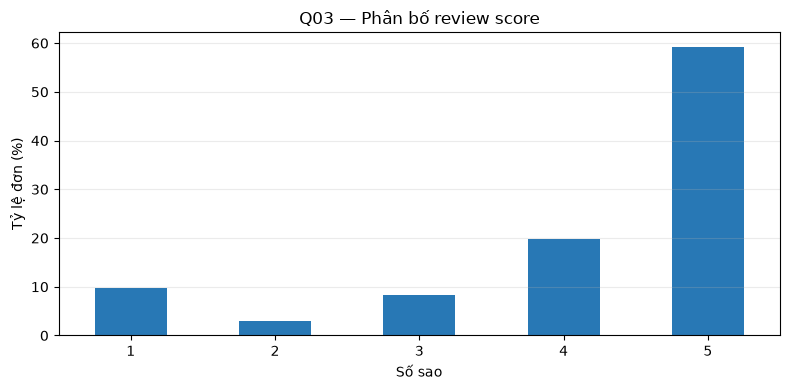

In [2]:
q03 = (
    review_orders.groupby("review_score")
    .agg(order_count=("order_id", "size"))
    .reindex(range(1, 6), fill_value=0)
)
q03["percentage"] = (q03["order_count"] / q03["order_count"].sum() * 100).round(2)
print(f"Điểm review trung bình toàn bộ: {review_orders['review_score'].mean():.2f}")
display(q03)

ax = q03["percentage"].plot(kind="bar", color="#2878B5", figsize=(8, 4))
ax.set(title="Q03 — Phân bố review score", xlabel="Số sao", ylabel="Tỷ lệ đơn (%)")
ax.set_xticklabels(q03.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Q04 — Giao trễ và giao đúng hạn liên quan đến review thế nào?

So sánh số đơn, điểm trung bình, tỷ lệ review thấp (≤2 sao) và tỷ lệ review tích cực (≥4 sao). Dùng Mann–Whitney U để so sánh phân bố điểm thứ bậc và Chi-square để kiểm tra mối liên hệ giữa giao trễ với review thấp. Kết quả kiểm định không chứng minh quan hệ nhân quả.


,order_count,avg_review_score,low_score_pct,positive_pct
is_late,,,,
Đúng hạn hoặc sớm,88978,4.29,9.23,82.71
Giao trễ,6351,2.27,62.37,26.72


Mann–Whitney U (trễ có điểm thấp hơn): U=102,194,480, p=0
Chi-square (giao trễ và review thấp có liên hệ): chi2=15,015.86, p=0
Kết luận ở mức alpha=0.05: có bằng chứng thống kê về khác biệt/liên hệ


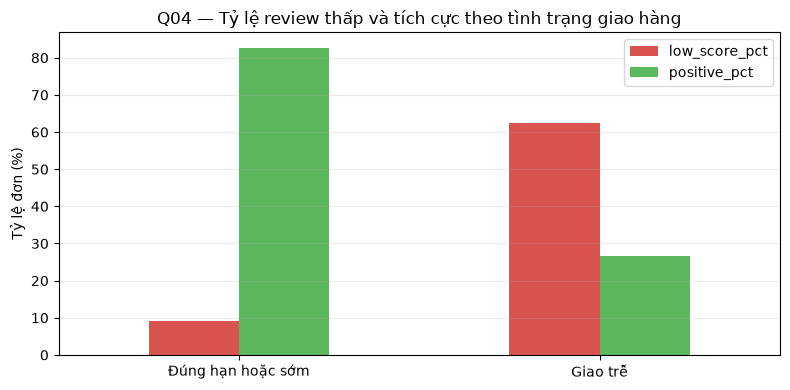

In [3]:
q04 = (
    review_orders.groupby("is_late")
    .agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
        positive_pct=("positive_review", "mean"),
    )
    .rename(index={False: "Đúng hạn hoặc sớm", True: "Giao trễ"})
)
q04[["low_score_pct", "positive_pct"]] *= 100
q04 = q04.round(2)
display(q04)

late_scores = review_orders.loc[review_orders["is_late"], "review_score"]
ontime_scores = review_orders.loc[~review_orders["is_late"], "review_score"]
mann_whitney = stats.mannwhitneyu(late_scores, ontime_scores, alternative="less")
contingency = pd.crosstab(review_orders["is_late"], review_orders["low_score"])
chi2, chi2_p, _, _ = stats.chi2_contingency(contingency)
print(f"Mann–Whitney U (trễ có điểm thấp hơn): U={mann_whitney.statistic:,.0f}, p={mann_whitney.pvalue:.3g}")
print(f"Chi-square (giao trễ và review thấp có liên hệ): chi2={chi2:,.2f}, p={chi2_p:.3g}")
print("Kết luận ở mức alpha=0.05:", "có bằng chứng thống kê về khác biệt/liên hệ" if max(mann_whitney.pvalue, chi2_p) < ALPHA else "chưa đủ bằng chứng thống kê")

q04[["low_score_pct", "positive_pct"]].plot(
    kind="bar", figsize=(8, 4), color=["#D9534F", "#5CB85C"]
)
plt.title("Q04 — Tỷ lệ review thấp và tích cực theo tình trạng giao hàng")
plt.xlabel("")
plt.ylabel("Tỷ lệ đơn (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Q05 — Mức độ giao trễ và review score

Phân nhóm `delay_days` giống SQL: đúng hạn/sớm, trễ 1–3 ngày, trễ 4–7 ngày và trễ trên 7 ngày. So sánh điểm trung bình, review thấp và review tích cực giữa các mức; nhóm có ít đơn cần được diễn giải thận trọng.


,order_count,avg_review_score,low_score_pct,positive_pct
delay_group,,,,
Sớm hoặc đúng hạn,88978,4.29,9.23,82.71
Trễ 1–3 ngày,1841,3.29,31.99,53.23
Trễ 4–7 ngày,1741,2.11,67.55,22.57
Trễ trên 7 ngày,2769,1.69,79.31,11.70


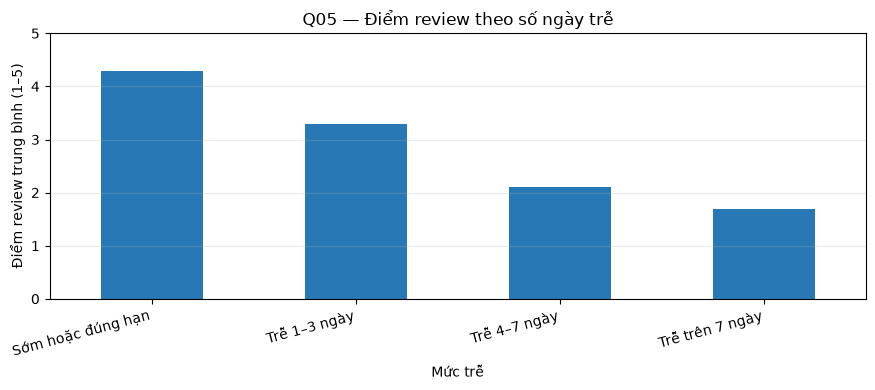

In [4]:
delay_labels = ["Sớm hoặc đúng hạn", "Trễ 1–3 ngày", "Trễ 4–7 ngày", "Trễ trên 7 ngày"]
review_orders["delay_group"] = pd.cut(
    review_orders["delay_days"], bins=[-np.inf, 0, 3, 7, np.inf], labels=delay_labels
)
q05 = (
    review_orders.groupby("delay_group", observed=False)
    .agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
        positive_pct=("positive_review", "mean"),
    )
)
q05[["low_score_pct", "positive_pct"]] *= 100
q05 = q05.round(2)
display(q05)

ax = q05["avg_review_score"].plot(kind="bar", figsize=(9, 4), color="#2878B5")
ax.set(title="Q05 — Điểm review theo số ngày trễ", xlabel="Mức trễ", ylabel="Điểm review trung bình (1–5)")
ax.set_ylim(0, 5)
ax.set_xticklabels(q05.index, rotation=15, ha="right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Q06 — Phí vận chuyển, tỷ lệ phí/giá và review score

Chia đơn thành bốn nhóm có kích thước gần bằng nhau (`NTILE(4)` trong SQL) theo tổng phí ship và theo tỷ lệ phí ship/giá trị hàng. So sánh review giữa các nhóm và đo liên hệ đơn điệu bằng Spearman. Tỷ lệ phí bị thiếu khi tổng giá trị hàng bằng 0; các dòng đó không tham gia phân tích tỷ lệ.


Theo tổng phí vận chuyển:


,order_count,avg_freight,avg_review_score,low_score_pct
freight_quartile,,,,
Q1 thấp,23833,10.45,4.32,9.08
Q2,23832,15.46,4.19,11.74
Q3,23832,19.78,4.18,12.10
Q4 cao,23832,45.38,3.94,18.17


Theo tỷ lệ phí vận chuyển/giá trị hàng:


,order_count,avg_freight_ratio_pct,avg_review_score,low_score_pct
freight_ratio_quartile,,,,
Q1 thấp,23833,8.41,4.20,12.32
Q2,23832,17.55,4.17,12.34
Q3,23832,29.18,4.15,13.01
Q4 cao,23832,68.18,4.11,13.43


Spearman tổng phí ship và review: rho=-0.088, p=1.09e-164
Spearman tỷ lệ phí/giá và review: rho=-0.031, p=1.58e-21


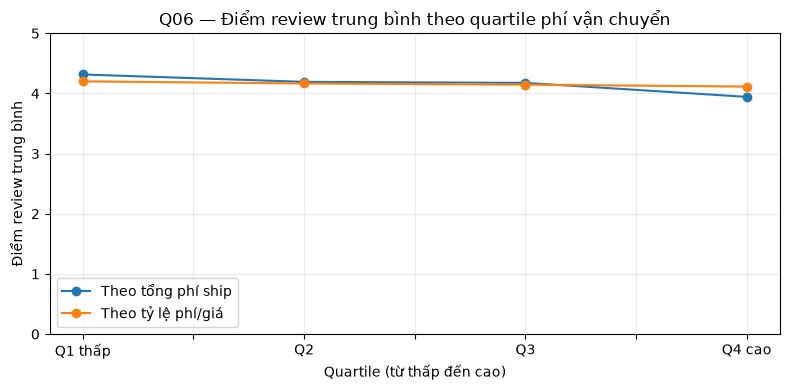

In [5]:
quartile_labels = ["Q1 thấp", "Q2", "Q3", "Q4 cao"]
for source, target in [
    ("total_freight", "freight_quartile"),
    ("freight_to_price_pct", "freight_ratio_quartile"),
]:
    review_orders[target] = pd.qcut(
        review_orders[source].rank(method="first"), q=4, labels=quartile_labels
    )

q06_freight = (
    review_orders.groupby("freight_quartile", observed=False)
    .agg(order_count=("order_id", "size"), avg_freight=("total_freight", "mean"),
         avg_review_score=("review_score", "mean"), low_score_pct=("low_score", "mean"))
)
valid_ratio = review_orders.dropna(subset=["freight_to_price_pct"])
q06_ratio = (
    valid_ratio.groupby("freight_ratio_quartile", observed=False)
    .agg(order_count=("order_id", "size"), avg_freight_ratio_pct=("freight_to_price_pct", "mean"),
         avg_review_score=("review_score", "mean"), low_score_pct=("low_score", "mean"))
)
q06_freight["low_score_pct"] *= 100
q06_ratio["low_score_pct"] *= 100
print("Theo tổng phí vận chuyển:")
display(q06_freight.round(2))
print("Theo tỷ lệ phí vận chuyển/giá trị hàng:")
display(q06_ratio.round(2))

freight_rho, freight_p = stats.spearmanr(review_orders["total_freight"], review_orders["review_score"])
ratio_rho, ratio_p = stats.spearmanr(valid_ratio["freight_to_price_pct"], valid_ratio["review_score"])
print(f"Spearman tổng phí ship và review: rho={freight_rho:.3f}, p={freight_p:.3g}")
print(f"Spearman tỷ lệ phí/giá và review: rho={ratio_rho:.3f}, p={ratio_p:.3g}")

q06_freight["avg_review_score"].plot(marker="o", label="Theo tổng phí ship", figsize=(8, 4))
q06_ratio["avg_review_score"].plot(marker="o", label="Theo tỷ lệ phí/giá")
plt.title("Q06 — Điểm review trung bình theo quartile phí vận chuyển")
plt.xlabel("Quartile (từ thấp đến cao)")
plt.ylabel("Điểm review trung bình")
plt.ylim(0, 5)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Q07 — Độ phức tạp đơn hàng và review score

Đối chiếu mức đánh giá theo số mặt hàng (`item_count`), số sản phẩm khác nhau (`distinct_products`) và số người bán (`seller_count`), theo nhóm tương ứng của SQL. Đây là so sánh mô tả, không khẳng định độ phức tạp làm thay đổi điểm.


Số mặt hàng


,order_count,avg_review_score,low_score_pct
basket_group,,,
1 mặt hàng,85857,4.21,11.24
2–3 mặt hàng,8551,3.67,25.92
4+ mặt hàng,921,3.36,34.09


Số sản phẩm khác nhau


,order_count,avg_review_score,low_score_pct
product_group,,,
1 sản phẩm,92197,4.18,12.06
2–3 sản phẩm,3043,3.38,33.62
4+ sản phẩm,89,3.18,39.33


Số người bán


,order_count,avg_review_score,low_score_pct
seller_group,,,
1 người bán,94081,4.17,12.31
Nhiều người bán,1248,2.86,47.36


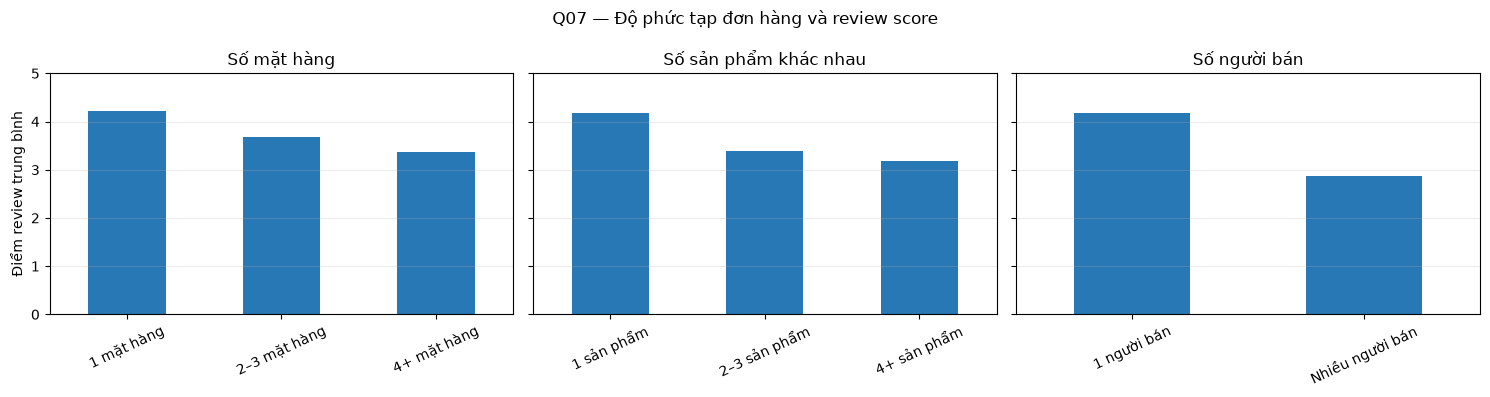

In [6]:
review_orders["basket_group"] = np.select(
    [review_orders["item_count"].eq(1), review_orders["item_count"].between(2, 3)],
    ["1 mặt hàng", "2–3 mặt hàng"], default="4+ mặt hàng"
)
review_orders["product_group"] = np.select(
    [review_orders["distinct_products"].eq(1), review_orders["distinct_products"].between(2, 3)],
    ["1 sản phẩm", "2–3 sản phẩm"], default="4+ sản phẩm"
)
review_orders["seller_group"] = np.where(
    review_orders["seller_count"].eq(1), "1 người bán", "Nhiều người bán"
)

q07_tables = {}
for column, title in [("basket_group", "Số mặt hàng"),
                      ("product_group", "Số sản phẩm khác nhau"),
                      ("seller_group", "Số người bán")]:
    summary = review_orders.groupby(column).agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
    )
    summary["low_score_pct"] *= 100
    q07_tables[title] = summary.round(2)
    print(title)
    display(q07_tables[title])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, summary) in zip(axes, q07_tables.items()):
    summary["avg_review_score"].plot(kind="bar", ax=ax, color="#2878B5")
    ax.set(title=title, xlabel="", ylabel="Điểm review trung bình")
    ax.set_ylim(0, 5)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Q07 — Độ phức tạp đơn hàng và review score")
fig.tight_layout()
plt.show()


## Q08 — Phương thức thanh toán, trả góp và review score

Theo `first_payment_type` và `max_installments` ở cấp đơn hàng, so sánh số đơn, điểm trung bình, tỷ lệ review thấp và tích cực. Các nhóm thanh toán có quy mô khác nhau nên luôn xem cả số lượng mẫu lẫn tỷ lệ.


Theo phương thức thanh toán:


,order_count,avg_installments,avg_review_score,low_score_pct,positive_pct
payment_type,,,,,
credit_card,73385,3.50,4.16,12.84,79.02
boleto,18970,1.00,4.16,12.51,78.87
voucher,1473,1.00,4.11,14.32,76.37
debit_card,1424,1.00,4.25,10.88,81.46
unknown,77,2.53,3.90,19.48,70.13


Theo số kỳ trả góp tối đa:


,order_count,avg_review_score,low_score_pct
installment_group,,,
1 kỳ,46327,4.19,11.87
2–3 kỳ,21888,4.15,12.85
4–6 kỳ,15534,4.13,13.47
7+ kỳ,11580,4.08,15.31


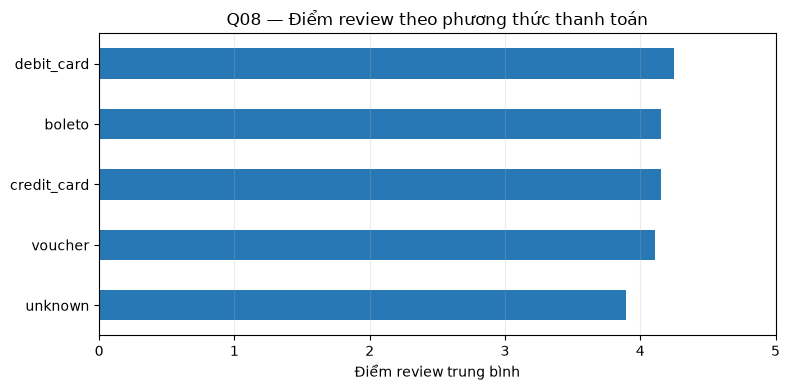

In [7]:
review_orders["payment_type"] = review_orders["first_payment_type"].fillna("unknown")
q08_payment = review_orders.groupby("payment_type").agg(
    order_count=("order_id", "size"),
    avg_installments=("max_installments", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
    positive_pct=("positive_review", "mean"),
).sort_values("order_count", ascending=False)
q08_payment[["low_score_pct", "positive_pct"]] *= 100
print("Theo phương thức thanh toán:")
display(q08_payment.round(2))

review_orders["installment_group"] = pd.cut(
    review_orders["max_installments"].fillna(0), bins=[-np.inf, 1, 3, 6, np.inf],
    labels=["1 kỳ", "2–3 kỳ", "4–6 kỳ", "7+ kỳ"]
)
q08_installments = review_orders.groupby("installment_group", observed=False).agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
)
q08_installments["low_score_pct"] *= 100
print("Theo số kỳ trả góp tối đa:")
display(q08_installments.round(2))

q08_payment["avg_review_score"].sort_values().plot(kind="barh", figsize=(8, 4), color="#2878B5")
plt.title("Q08 — Điểm review theo phương thức thanh toán")
plt.xlabel("Điểm review trung bình")
plt.ylabel("")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## Q09 — Xu hướng review theo tháng đặt hàng

Tổng hợp số đơn, điểm trung bình, tỷ lệ review tích cực và tỷ lệ review thấp theo `purchase_year_month`, cùng mốc tháng đặt hàng của SQL. Số đơn trong mỗi tháng là thiết yếu để nhận biết tháng có ít quan sát; thay đổi theo thời gian không tự nó chứng minh nguyên nhân.


,order_count,avg_review_score,positive_pct,low_score_pct
purchase_year_month,,,,
2016-10-01,260,4.01,75.38,16.54
2016-12-01,1,5.00,100.00,0.00
2017-01-01,729,4.20,79.84,11.93
2017-02-01,1634,4.21,79.44,11.02
2017-03-01,2506,4.19,79.93,11.13
2017-04-01,2276,4.13,78.08,13.01
2017-05-01,3490,4.24,80.97,10.00
2017-06-01,3083,4.22,80.60,10.70
2017-07-01,3809,4.26,81.46,9.90


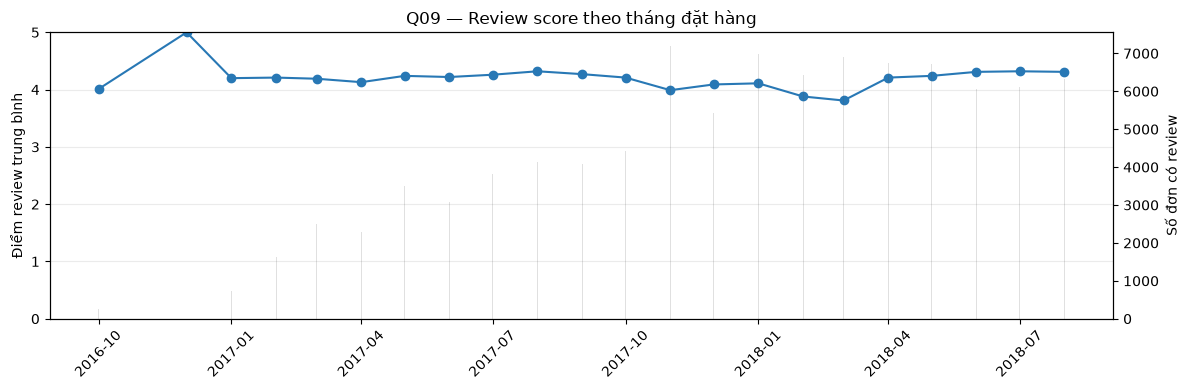

In [8]:
q09 = review_orders.groupby("purchase_year_month").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
).sort_index()
q09[["positive_pct", "low_score_pct"]] *= 100
q09 = q09.round(2)
display(q09)

fig, ax_score = plt.subplots(figsize=(12, 4))
ax_score.plot(q09.index, q09["avg_review_score"], color="#2878B5", marker="o", label="Điểm review TB")
ax_score.set_ylabel("Điểm review trung bình")
ax_score.set_ylim(0, 5)
ax_score.tick_params(axis="x", rotation=45)
ax_count = ax_score.twinx()
ax_count.bar(q09.index, q09["order_count"], alpha=0.18, color="#555555", label="Số đơn")
ax_count.set_ylabel("Số đơn có review")
ax_score.set_title("Q09 — Review score theo tháng đặt hàng")
ax_score.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## Q10 — Mức hài lòng theo bang khách hàng

So sánh số đơn, điểm trung bình, tỷ lệ review tích cực/thấp, tỷ lệ giao trễ và thời gian giao theo `customer_state`. Bảng giữ nguyên các bang như SQL; biểu đồ cho phép quan sát liệu bang có tỷ lệ giao trễ cao hơn cũng có điểm trung bình thấp hơn. Lưu ý cỡ mẫu khi so sánh bang nhỏ.


,order_count,avg_review_score,positive_pct,low_score_pct,late_rate_pct,avg_delivery_days
customer_state,,,,,,
MA,706,3.82,69.97,20.11,17.28,21.43
AL,393,3.85,71.76,21.12,20.61,24.41
RR,41,3.90,68.29,14.63,12.20,29.39
SE,332,3.90,72.29,18.98,15.06,21.45
PA,924,3.92,72.40,17.86,10.82,23.63
BA,3213,3.93,72.92,16.99,11.89,19.24
CE,1272,3.94,72.80,17.14,13.68,21.22
RJ,12136,3.97,73.48,18.27,11.95,15.24
PI,470,3.99,75.11,16.17,13.62,19.48


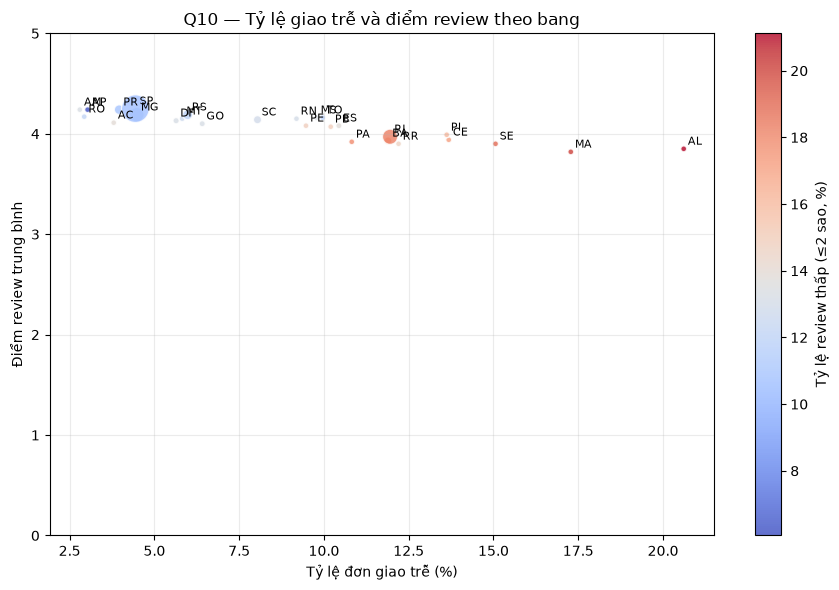

Spearman giữa tỷ lệ giao trễ và điểm review cấp bang: rho=-0.880, p=1.46e-09
Tương quan trên các bang không phải kiểm định nhân quả ở cấp đơn hàng.


In [9]:
q10 = review_orders.groupby("customer_state").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
    late_rate_pct=("is_late", "mean"),
    avg_delivery_days=("delivery_days", "mean"),
)
q10[["positive_pct", "low_score_pct", "late_rate_pct"]] *= 100
q10 = q10.sort_values(["avg_review_score", "order_count"], ascending=[True, False]).round(2)
display(q10)

fig, ax = plt.subplots(figsize=(9, 6))
points = ax.scatter(
    q10["late_rate_pct"], q10["avg_review_score"],
    s=np.maximum(q10["order_count"] / 100, 18), c=q10["low_score_pct"],
    cmap="coolwarm", alpha=0.8, edgecolors="white"
)
for state, row in q10.iterrows():
    ax.annotate(state, (row["late_rate_pct"], row["avg_review_score"]),
                fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set(title="Q10 — Tỷ lệ giao trễ và điểm review theo bang",
       xlabel="Tỷ lệ đơn giao trễ (%)", ylabel="Điểm review trung bình")
ax.set_ylim(0, 5)
ax.grid(alpha=0.25)
fig.colorbar(points, ax=ax, label="Tỷ lệ review thấp (≤2 sao, %)")
fig.tight_layout()
plt.show()

state_rho, state_p = stats.spearmanr(q10["late_rate_pct"], q10["avg_review_score"])
print(f"Spearman giữa tỷ lệ giao trễ và điểm review cấp bang: rho={state_rho:.3f}, p={state_p:.3g}")
print("Tương quan trên các bang không phải kiểm định nhân quả ở cấp đơn hàng.")


## Tổng kết và liên hệ với SQL

Notebook này giữ cùng câu hỏi, đơn vị phân tích và nguồn `v_review_order_features` với Q03–Q10 trong `03_analysis_SQL.ipynb`. SQL cung cấp các bảng tổng hợp để đối chiếu; Python bổ sung biểu đồ và kiểm định thống kê cho mối liên hệ giữa review score với trải nghiệm giao hàng, vận chuyển, giỏ hàng, thanh toán, thời điểm và địa lý.

Khi báo cáo, nên nêu cùng lúc cỡ mẫu, mức chênh lệch thực tế và p-value; không diễn giải p-value nhỏ như bằng chứng nhân quả. Với mô hình hóa ở notebook tiếp theo, cần tách riêng biến sẵn có tại thời điểm đặt hàng khỏi biến chỉ biết sau khi giao để tránh data leakage.
